# Chapitre 15 - Exercices 15.5 à 15.7

- **15.5** : corrélation d'échantillonnage entre deux arbres d'une forêt (formule (15.12)) ;
- **15.6** : sensibilité de la forêt au paramètre $m$ sur les données spam (erreurs OOB et test) ;
- **15.7** : importance par permutation en régression linéaire, $\mathbb E_P[\mathrm{RSS}^*_j-\mathrm{RSS}]=2\hat\beta_j^2$.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import datasets
from esl import ch15_forets as rf
set_style()

## Exercice 15.5 : Corrélation entre deux arbres d'une forêt

**Énoncé.** Montrer que la corrélation d'échantillonnage entre deux arbres d'une forêt
aléatoire, en un point $x$, vaut
$$\rho(x)=\frac{\operatorname{Var}_{\mathbf Z}\big[\mathbb E_{\Theta\mid\mathbf Z}T(x;\Theta(\mathbf Z))\big]}{\operatorname{Var}_{\mathbf Z}\big[\mathbb E_{\Theta\mid\mathbf Z}T(x;\Theta(\mathbf Z))\big]+\mathbb E_{\mathbf Z}\operatorname{Var}_{\Theta\mid\mathbf Z}\big[T(x;\Theta(\mathbf Z))\big]}.\qquad(15.12)$$
Le numérateur est $\operatorname{Var}_{\mathbf Z}[\hat f_{\rm rf}(x)]$ ; le second terme du
dénominateur est la variance conditionnelle moyenne due à la randomisation de la forêt.

### Cadre

On tire un échantillon d'apprentissage $\mathbf Z$, puis, **sachant $\mathbf Z$**, deux
aléas $\Theta_1,\Theta_2$ **indépendants et de même loi** (bootstrap + tirages des
variables candidates). On pose $T_k=T(x;\Theta_k(\mathbf Z))$, $k=1,2$. La corrélation
(15.6) est $\rho(x)=\operatorname{corr}(T_1,T_2)$, calculée sous la loi jointe de
$(\mathbf Z,\Theta_1,\Theta_2)$.

Rappelons les deux formules de décomposition (voir aussi l'exercice 15.4) :
$$\operatorname{Var}U=\mathbb E\big[\operatorname{Var}(U\mid\mathbf Z)\big]+\operatorname{Var}\big(\mathbb E[U\mid\mathbf Z]\big),\qquad
\operatorname{Cov}(U,V)=\mathbb E\big[\operatorname{Cov}(U,V\mid\mathbf Z)\big]+\operatorname{Cov}\big(\mathbb E[U\mid\mathbf Z],\mathbb E[V\mid\mathbf Z]\big).$$

### Démonstration

**Espérances conditionnelles.** $\Theta_1$ et $\Theta_2$ ayant la même loi sachant
$\mathbf Z$, $\mathbb E[T_1\mid\mathbf Z]=\mathbb E[T_2\mid\mathbf Z]=\mathbb E_{\Theta\mid\mathbf Z}T(x;\Theta(\mathbf Z))=\hat f_{\rm rf}(x)$
(la forêt limite (15.4)).

**Covariance.** Sachant $\mathbf Z$, $T_1$ et $T_2$ sont des fonctions respectives de
$\Theta_1$ et $\Theta_2$, qui sont indépendants : donc
$\operatorname{Cov}(T_1,T_2\mid\mathbf Z)=0$. La formule de la covariance totale donne
$$\operatorname{Cov}(T_1,T_2)=0+\operatorname{Cov}\big(\hat f_{\rm rf}(x),\hat f_{\rm rf}(x)\big)=\operatorname{Var}_{\mathbf Z}\hat f_{\rm rf}(x).$$

**Variance.** Pour $k=1,2$, la formule de la variance totale donne (c'est (15.9))
$$\operatorname{Var}T_k=\operatorname{Var}_{\mathbf Z}\hat f_{\rm rf}(x)+\mathbb E_{\mathbf Z}\operatorname{Var}_{\Theta\mid\mathbf Z}T(x;\Theta(\mathbf Z)).$$

**Conclusion.** Les deux variances étant égales,
$\rho(x)=\operatorname{Cov}(T_1,T_2)/\operatorname{Var}T_1$, ce qui est exactement (15.12). $\blacksquare$

> **Intuition.** Deux arbres construits sur le même $\mathbf Z$ ne se « ressemblent » qu'à
> travers $\mathbf Z$ : la part commune de leur variabilité est la variabilité de la forêt
> limite, la part propre à chacun est l'aléa $\Theta$. Plus la randomisation est forte
> (petit $m$), plus la part propre grandit et plus $\rho(x)$ est petit. Combinée à (15.5),
> on retrouve $\operatorname{Var}\hat f_{\rm rf}(x)=\rho(x)\sigma^2(x)$ avec
> $\sigma^2(x)=\operatorname{Var}T_1$.

### Vérification numérique sur le modèle (15.8)

$Y=\frac1{\sqrt{50}}\sum_{j=1}^{50}X_j+\varepsilon$. Nous tirons 200 échantillons
$\mathbf Z$ de taille 100 et, pour chacun, une forêt « maison » de 20 arbres ($m=10$,
$n_{\min}=5$), évaluée en 200 points $x$.

In [2]:
rng = np.random.RandomState(0)
Xtest, _, mu_test = rf.simuler_additif(200, rng=rng)
nZ, nT = 200, 20
T = np.empty((nZ, nT, len(Xtest)))
t0 = time.time()
for z in range(nZ):
    X, y, _ = rf.simuler_additif(100, rng=rng)
    T[z] = rf.ForetAleatoire(B=nT, m=10, nmin=5, seed=z).fit(X, y).predictions_arbres(Xtest)
print("temps : %.0f s" % (time.time() - t0))

temps : 7 s


**Formule (15.12)** (fonction `decomposition_variance`, qui estime les deux termes) contre
**corrélation empirique directe** entre des paires d'arbres $(T_{z,2k},T_{z,2k+1})$
construits sur le même échantillon, calculée point par point sur les $200\times10$ paires.

In [3]:
d = rf.decomposition_variance(T)
A = T[:, 0::2, :].reshape(-1, len(Xtest))
Bp = T[:, 1::2, :].reshape(-1, len(Xtest))
rho_direct = np.array([np.corrcoef(A[:, i], Bp[:, i])[0, 1] for i in range(len(Xtest))])
print("rho(x) moyen : formule (15.12) %.3f ; corrélation empirique directe %.3f"
      % (d["rho"].mean(), rho_direct.mean()))

rho(x) moyen : formule (15.12) 0.043 ; corrélation empirique directe 0.041


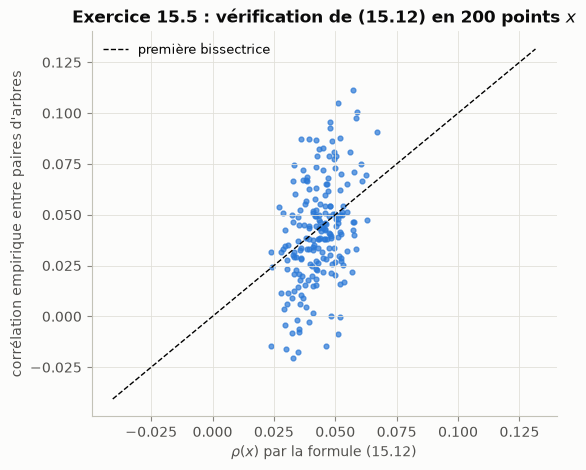

In [4]:
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(d["rho"], rho_direct, s=12, color=BLUE, alpha=0.7)
lim = [min(d["rho"].min(), rho_direct.min()) - 0.02, max(d["rho"].max(), rho_direct.max()) + 0.02]
ax.plot(lim, lim, "k--", lw=1, label="première bissectrice")
ax.set_xlabel(r"$\rho(x)$ par la formule (15.12)")
ax.set_ylabel(r"corrélation empirique entre paires d'arbres")
ax.set_title("Exercice 15.5 : vérification de (15.12) en 200 points $x$")
ax.legend()
plt.show()

Les points se dispersent autour de la bissectrice (chaque estimation ponctuelle est bruitée,
2000 paires seulement), et les moyennes concordent.

**Covariance conditionnelle nulle.** Fixons maintenant **un** échantillon $\mathbf Z$ et
tirons 400 arbres : les corrélations entre arbres pairs et impairs, calculées sur les 200
tirages de $\Theta$, doivent être nulles aux fluctuations près (écart-type
$\approx1/\sqrt{200}$).

In [5]:
X, y, _ = rf.simuler_additif(100, rng=rng)
foret_Z = rf.ForetAleatoire(B=400, m=10, nmin=5, seed=123).fit(X, y)
Pz = foret_Z.predictions_arbres(Xtest)
rho_cond = np.array([np.corrcoef(Pz[0::2, i], Pz[1::2, i])[0, 1] for i in range(len(Xtest))])
print("corrélation conditionnelle moyenne : %.4f (écart-type entre points %.3f ; 1/sqrt(200) = %.3f)"
      % (rho_cond.mean(), rho_cond.std(), 1 / np.sqrt(200)))

corrélation conditionnelle moyenne : 0.0003 (écart-type entre points 0.070 ; 1/sqrt(200) = 0.071)


Enfin, calculons la quantité contre laquelle le livre met en garde : la corrélation
entre arbres **ajustés** sur un même $\mathbf Z$, vus comme des vecteurs de prédictions
(corrélation calculée sur les points $x$, pas sur les tirages de $\mathbf Z$). C'est une
autre quantité, qui dépend de l'échantillon $\mathbf Z$ particulier et de la répartition
des points $x$, et qui n'intervient pas dans la variance de la forêt.

In [6]:
C = np.corrcoef(Pz[:50])
corr_vecteurs = C[np.triu_indices(50, 1)].mean()
print("corrélation moyenne entre vecteurs de prédictions d'arbres ajustés : %.3f" % corr_vecteurs)
print("à comparer à rho(x) moyen : %.3f" % d["rho"].mean())

corrélation moyenne entre vecteurs de prédictions d'arbres ajustés : 0.057
à comparer à rho(x) moyen : 0.043


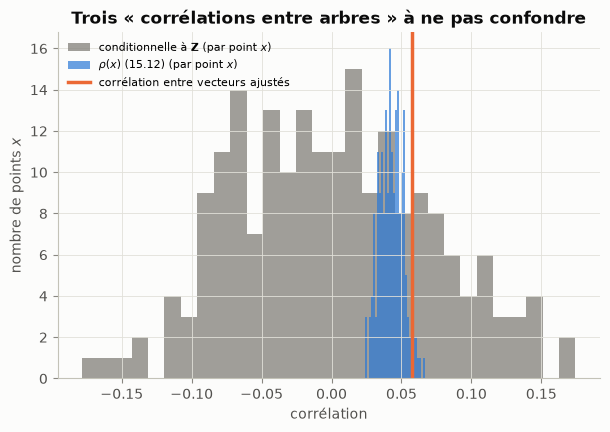

In [7]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.hist(rho_cond, bins=30, color=GRAY, alpha=0.8, label=r"conditionnelle à $\mathbf{Z}$ (par point $x$)")
ax.hist(d["rho"], bins=30, color=BLUE, alpha=0.7, label=r"$\rho(x)$ (15.12) (par point $x$)")
ax.axvline(corr_vecteurs, color=ORANGE, lw=2.5, label="corrélation entre vecteurs ajustés")
ax.set_xlabel("corrélation")
ax.set_ylabel("nombre de points $x$")
ax.set_title("Trois « corrélations entre arbres » à ne pas confondre")
ax.legend(fontsize=8)
plt.show()

> **À retenir.** $\operatorname{Cov}(T_1,T_2)=\operatorname{Var}_{\mathbf Z}\hat f_{\rm rf}(x)$
> car les arbres sont indépendants sachant $\mathbf Z$ ; d'où (15.12). La corrélation
> $\rho(x)$ provient **uniquement** de la variabilité de l'échantillon ; elle n'a rien à
> voir avec la corrélation entre les vecteurs de prédictions d'arbres déjà ajustés,
> même si, dans cet exemple, les deux sont d'un ordre de grandeur comparable.